# Diagnose a failing solve

This page breaks the plate loop of [Get a steady solve to converge](get-a-steady-solve-to-converge.ipynb) and reads each fault in the order that costs least: the report, two hand checks, the residual of each calculation, the trajectory a failed transient keeps. A table maps other symptoms to their causes.

In [1]:
from functools import partial

import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rc

rc("font", family="serif", size=15)

from stream import State
from stream.aggregator import Solution
from stream.analysis.debugging import debug_derivatives, debug_guess_flows
from stream.analysis.report import report
from stream.calculations import ChannelAndContacts, Fuel, Gravity, HeatExchanger, Junction, KirchhoffWDerivatives, Pump, Solid
from stream.composition import FlowGraph, flow_edge, symmetric_plate, symmetric_plate_steady_state, uniform_x_power_shape, x_boundaries
from stream.jacobians import ALG_jacobian, DAE_jacobian
from stream.physical_models.heat_transfer_coefficient import spl_htc, wall_heat_transfer_coeff
from stream.physical_models.pressure_drop import friction_factor, pressure_diff, rectangular_laminar_correction
from stream.pipe_geometry import EffectivePipe
from stream.solvers import TransientRuntimeError
from stream.substances import light_water

## A loop to break

The loop is the steady page's, 2 kW in the plate and 6 kPa of pump head. `build` takes the plate's `funcs`, so a build can leave the power out.

In [2]:
length, width = 0.7, 0.070
clad_N, fuel_N, clad_w, meat_w = 2, 8, 0.0005, 0.0006
z = np.linspace(0.0, length, 11)
meat = np.zeros((len(z) - 1, fuel_N + 2 * clad_N), dtype=bool)
meat[:, clad_N:-clad_N] = True
fuel = Fuel(
    z_boundaries=z,
    x_boundaries=x_boundaries(clad_N, fuel_N, clad_w, meat_w),
    material=Solid.from_array(np.where(meat, Solid(3500, 750, 40), Solid(2700, 900, 167))),
    y_length=width,
    power_shape=uniform_x_power_shape(len(z) - 1, fuel_N, clad_N, clad_w, meat_w, length),
    meat_indices=meat,
    name="Plate",
)
pipe = EffectivePipe.rectangular(length=length, edge1=width, edge2=0.0022, heated_edge=width)
aspect_ratio, re_bounds = pipe.depth / pipe.width, (2000.0, 5000.0)
h_spl = spl_htc("regime_dependent", re_bounds=re_bounds, Lh=length, aspect_ratio=aspect_ratio)
f = friction_factor("regime_dependent", re_bounds=re_bounds, k_R=rectangular_laminar_correction(aspect_ratio))
channel = ChannelAndContacts(
    z_boundaries=z,
    fluid=light_water,
    pipe=pipe,
    h_wall_func=partial(wall_heat_transfer_coeff, h_spl=h_spl),
    pressure_func=partial(pressure_diff, f=f),
    name="Channel",
)
power, p_top, T_hx = 2e3, 1.8e5, 38.0


def build(plate_funcs):
    top, bottom = Junction(name="Top"), Junction(name="Bottom")
    pump = Pump(pressure=6e3, name="Pump")
    riser = Gravity(light_water, disposition=-length, name="Riser")
    hx_in, hx_out = HeatExchanger(outlet=T_hx, name="HXIn"), HeatExchanger(outlet=T_hx, name="HXOut")
    fg = FlowGraph(
        flow_edge((top, bottom), channel),
        flow_edge((bottom, top), pump, hx_in, riser, hx_out),
        reference_node=(top, p_top),
        abs_pressure_comps=[channel],
        inertial_comps=[channel],
        k_constructor=KirchhoffWDerivatives,
    )
    agr = fg.aggregator + symmetric_plate(channel, fuel, funcs=plate_funcs).to_aggregator()
    return agr, fg, pump

## Read the report first

`report(agr)` from `stream.analysis.report`, read as in [Write a calculation](write-a-calculation.ipynb#Build-it-alone-and-read-the-report), runs before any solve.

In [3]:
agr, fg, pump = build({})
report(agr)

Contains 186 Equations, 9 Nodes, 28 Edges.

| Calculation | Type | Equation No. | Unset | Set Externally | Missing |
| :---------- | :--- | :----------- | :---- | :------------- | :------ |
| Top | Junction | 0 - 1 |  |  |  |
| Channel | ChannelAndContacts | 1 - 32 |  |  |  |
| Bottom | Junction | 32 - 33 |  |  |  |
| Pump | Pump | 33 - 35 | pressure, mdot0 |  |  |
| HXIn | HeatExchanger | 35 - 37 |  |  |  |
| Riser | Gravity | 37 - 39 |  |  |  |
| HXOut | HeatExchanger | 39 - 41 |  |  |  |
| Kirchhoff | KirchhoffWDerivatives | 41 - 46 |  |  |  |
| Plate | Fuel | 46 - 186 | power, T_top, T_bottom, h_top, h_bottom |  | power |


The plate's **Missing** column names `power`. Binding it is the fix.

In [4]:
agr, fg, pump = build({fuel: dict(power=power)})
print(f"plate inputs set externally: {list(agr.funcs[fuel])}")

plate inputs set externally: ['power']


The plate now takes its power from `funcs`.

## Check the answer by hand

A converged solve still has to be the plant one meant. The cell runs the energy balance of [Hand checks](../LOFAPoolReactor.ipynb#Hand-checks) on the channel and adds the components' `pressure` gains around the loop.

In [5]:
def seed(mdot):
    hydraulics = fg.guess_steady_state({channel: mdot, pump: mdot}, T_hx)
    pair = symmetric_plate_steady_state(channel, fuel, mdot=mdot, p_abs=p_top, power=power, Tin=T_hx)
    return State.merge(hydraulics, pair)


K = fg.kirchhoff
state = agr.save(agr.solve_steady(seed(0.2), jac=ALG_jacobian(agr), tol=1e-10))
mdot, T_out = state[K.name][K.component_edge(channel)], state["Channel"]["T_out"]
cp = float(light_water.specific_heat((T_out + T_hx) / 2))
gains = {name: float(state[name]["pressure"]) for name in ("Channel", "Pump", "HXIn", "Riser", "HXOut")}
print(f"flow:                {mdot:.4f} kg/s")
print(f"mdot cp dT:          {mdot * cp * (T_out - T_hx):.1f} W")
print("gains [Pa]:          " + ", ".join(f"{k} {v:.1f}" for k, v in gains.items()))
print(f"|sum of the gains|:  {abs(sum(gains.values())):.3f} Pa")

flow:                0.2227 kg/s
mdot cp dT:          2000.0 W
gains [Pa]:          Channel 810.5, Pump 6000.0, HXIn 0.0, Riser -6810.5, HXOut 0.0
|sum of the gains|:  0.000 Pa


The coolant carries off about 2000 W of the 2 kW, and the gains cancel. A balance that misses points at the wiring, not the solver.

## Find the calculation that carries the residual

The guess below runs the loop backward, at -0.2 kg/s. `debug_derivatives(agr, guess)` from `stream.analysis.debugging` evaluates $F$, the aggregator's functional, at the guess and returns it as a `State`: the residual of each algebraic row, the derivative of each differential one. The cell prints each calculation's largest entry, then `debug_guess_flows`, the Kirchhoff flow rows.

In [6]:
wrong = seed(-0.2)
for calc, rows in debug_derivatives(agr, wrong).items():
    print(f"{calc:>9}: {max(np.max(np.abs(v)) for v in rows.values()):.2f}")
print({k: round(float(v), 2) for k, v in debug_guess_flows(agr, wrong).items()})

      Top: 2.39
  Channel: 0.00
   Bottom: 0.00
     Pump: 0.00
     HXIn: 0.00
    Riser: 0.00
    HXOut: 0.00
Kirchhoff: 10977.00
    Plate: 0.00
{'(Top -> Bottom, 0)': 0.0, '(Bottom -> Top, 0)': 0.0, '(Top -> Bottom, mdot2 0)': 10977.0, '(Bottom -> Top, mdot2 0)': 0.0}


Two calculations carry it. Kirchhoff's keys are offset from its equations, so a residual sits under another variable's key: the loop law, missing zero by about 11 kPa, under `(Top -> Bottom, mdot2 0)`. The junction at the top is about 2.4 K from its mixing temperature. A seed with the physical sign is the cure.

## Locate where a transient died

[When a run fails](run-a-transient-and-set-tolerances.ipynb#When-a-run-fails) keeps the trajectory of a `TransientRuntimeError`. Its message starts with `At t = ` and the last output time reached, so the run died in the interval after it. The cell doubles the pump head at once and runs with `max_steps=50` on a grid that goes to 1 s in tenths, then to 10 s.

TransientRuntimeError between 1.0 s and 10.0 s


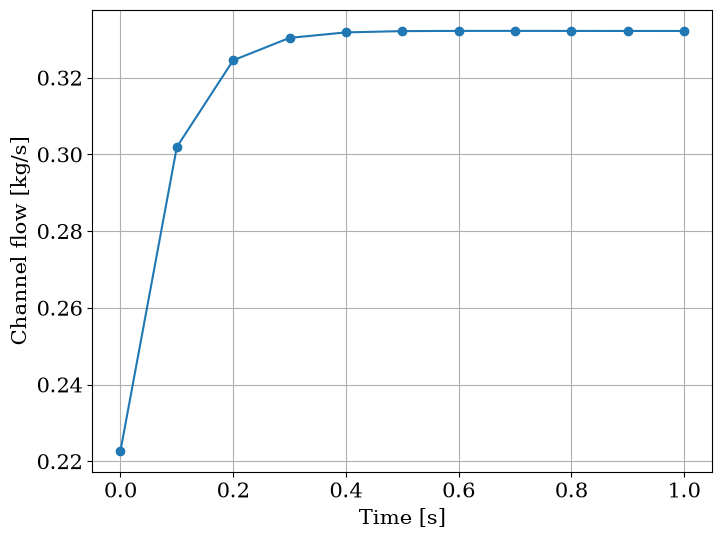

In [7]:
y0 = agr.load(state)
row = agr.var_index(K, K.component_edge(channel))
pump.p = 1.2e4
grid = np.concatenate([np.linspace(0.0, 1.0, 11), [10.0]])
try:
    reached = agr.solve(y0, grid, jacfn=DAE_jacobian(agr), max_steps=50, err_handler=lambda *args: None)
except TransientRuntimeError as err:
    t_last = float(str(err).split(":")[0].removeprefix("At t = "))
    print(f"{type(err).__name__} between {t_last:.1f} s and {grid[grid > t_last][0]:.1f} s")
    reached = Solution(err.t, err.y)
fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(reached.time, reached.data[:, row], marker="o")
ax.set_xlabel("Time [s]")
ax.set_ylabel("Channel flow [kg/s]")
ax.grid()
plt.show()

The first second shows the flow climbing to its new level. Raising `max_steps`, or adding output times to that interval, lets it finish.

## Symptoms and causes

| symptom | cause | what to do | where |
|---|---|---|---|
| **Missing** lists an input | nothing supplies it and it has no default | draw the edge or bind it in `funcs` | [Bind inputs and time schedules](bind-inputs-and-schedules.ipynb) |
| one calculation's residual far above the rest | its part of the guess, or its wiring | reseed from the helpers | [Get a steady solve to converge](get-a-steady-solve-to-converge.ipynb) |
| every flow about zero | no net head: a pump left at `pump.p = 0.0` on an unheated loop | check each pump's head | [Wire a flow network](wire-a-flow-network.ipynb#Junctions-and-edges) |
| a solved flow of the opposite sign | an edge drawn against the flow, or a `Gravity` whose `disposition` has the wrong sign | check each edge and height | [Sign conventions](../explanation/sign-conventions.rst) |
| `TransientRuntimeError` at `t = 0` | a `y0` that is not a solved state, or a start that needs more than `max_steps` | solve steady first; raise `max_steps` | [Start from the steady state](run-a-transient-and-set-tolerances.ipynb#Start-from-the-steady-state), [Tolerances, a Jacobian and a step cap](run-a-transient-and-set-tolerances.ipynb#Tolerances,-a-Jacobian-and-a-step-cap) |
| a run that crawls or dies after an event | the step collapses at the restart, one edge pinned by an algebraic law | `exclude_algvar_from_error=True` | [Loops with events](run-a-transient-and-set-tolerances.ipynb#Loops-with-events) |
| NumPy warns of a division by zero or an invalid value | an iterate far from the answer, where a friction or heat-transfer law divides by zero | reseed nearer the answer | [Pump off](get-a-steady-solve-to-converge.ipynb#Pump-off) |
| `SaturationReachedError` | a channel with `stop_at_saturation=True` reached bulk saturation | less power, more pressure or more flow | [When a channel saturates](trip-stop-and-restart.ipynb#When-a-channel-saturates); [A stuck flapper](../LOFAVariations.ipynb#A-stuck-flapper) at scale |

A run that completes and still looks wrong is settled by [When a result looks wrong](../LOFAVariations.ipynb#When-a-result-looks-wrong). The usual next task: [Read results](read-results.ipynb).